# 03 · Models and reconciliation: can anything beat momentum, and do the numbers add up?

Notebook 02 set the bar: *momentum* (the last 12 months' growth continues) is hard to beat in calm
markets and badly late at turning points. This notebook tries three models on every node, then
makes the forecasts **coherent**: counties that add up to their metro and state, which add up to
the nation.

**The models** (details in `src/housing/models.py`; all fitted with closed-form least squares, so
the full backtest runs in minutes):

| Model | Idea | In plain words |
|---|---|---|
| **ar2** | ARIMA(2,1,0) with drift per node, 5-year window | each place extrapolates its own recent rhythm |
| **panel** | direct regression, pooled across the nodes of a level, one per horizon: recent growth (1, 3, 12 months and the year before), national growth, mortgage-rate change and rate vs its 3-year average, unemployment change | what usually happens next to a place with this recent history, in this rate environment |
| **zillow_style** | Zillow's published structure: national forecast x each node's (shrunk) sensitivity to the nation + a fading local gap | the nation sets the tide; each place rides it with its own beta |
| **combo** | equal-weight average of ar2 and panel | two forecasters who look at different evidence, averaged |

**Reconciliation**, in plain words: think of a company budget. Each department forecasts its
own spending, and the department numbers never add up to the CFO's total. You could just add up
the departments (*bottom-up*), or adjust everyone a little, adjusting most the forecasts that
have been least reliable. That is **MinTrace**: the coherent set of forecasts closest to the
originals, where "close" is measured by each forecast's past error (and, for *mint_shrink*, how
errors move together). Four versions are compared: bottom-up, wls_struct (weights from the tree
shape only), wls_var (weights from each node's past error variance) and mint_shrink (full
error covariance, shrunk).

**Scoring.** All methods, baselines included, are scored on the same 48 quarterly forecast dates
(January 2014 to the last date with a 12-month outcome), at 1, 3, 6 and 12 months ahead.

| | |
|---|---|
| **Question** | Do models beat momentum, especially at turning points, and does making forecasts add up help or hurt accuracy? |
| **Answer** | Yes. The chosen forecast averages a per-place ARIMA with a rates-aware panel regression, then adds counties up to every level (bottom-up). It cuts the metro 12-month error from 5.9 pp (momentum) to 5.1 pp, 14% lower. In the 2022-23 rate shock the drop is from 10.6 pp to 6.0 pp, 44% lower. Making the numbers add up costs almost nothing: at metro and county level, bottom-up is as accurate as the best MinTrace variant. Weighting by tree shape alone (wls_struct) is badly wrong once forecasts are in dollars. The intervals are too narrow: nominal 80% intervals cover about 73% of metro outcomes at 12 months. |
| **Next** | Notebook 04 runs the rate and recession scenarios through the chosen model. Notebook 05 tests this choice on later data: a year out, it does not hold. |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from housing import backtest as bt
from housing import panel
from housing.config import data_dirs, use_synthetic
from housing.pipeline import BASES, RECONCILERS, eval_origins, run_all
from housing.plots import COLORS, save, style, write_metrics

style()
if use_synthetic():
    print("SYNTHETIC DATA: numbers below are made up (CI run).")
out = data_dirs()[1]
if (out / "backtest_models.parquet").exists() and not use_synthetic():
    long = pd.read_parquet(out / "backtest_models.parquet")       # written by scripts/run_models.py
    coefs = pd.read_parquet(out / "panel_coefficients.parquet")
else:
    r = run_all(save=False)
    long, coefs = r["long"], r["coefs"]
Y, S_df, tags, nodes = panel.load_hierarchy()
L = bt.log_wide(Y)
evo = eval_origins(L)
res = bt.add_context(long, bt.mase_scale(L))
del long
print(f"{len(evo)} forecast dates, {res['method'].nunique()} methods, {len(res):,} scored forecasts")

47 forecast dates, 26 methods, 9,903,088 scored forecasts


## 1. Base models, before reconciliation

RMSE of growth (pp). The column to watch is metro and county at 12 months, where momentum scored
about 6 pp in notebook 02.

In [2]:
order = ["National", "State", "Metro", "County"]
base_methods = ["naive", *BASES]
scores = bt.score(res)
write_metrics("03_scores_all", scores)
base = scores[scores["method"].isin(base_methods)]
board = base.pivot_table(index=["level", "method"], columns="h", values="rmse_pp", observed=True).reindex(order, level=0)
board.round(2)

h                        1     3     6     12
level    method                              
National ar2           0.11  0.73  2.26  4.74
         combo         0.12  0.73  1.92  3.83
         momentum      0.45  1.42  2.77  5.27
         naive         0.68  2.01  3.81  6.99
         panel         0.13  0.91  2.67  5.88
         zillow_style  0.13  0.91  2.67  5.88
State    ar2           0.16  0.90  2.49  5.21
         combo         0.15  0.85  2.17  4.65
         momentum      0.48  1.50  2.89  5.56
         naive         0.72  2.12  4.02  7.40
         panel         0.17  0.97  2.58  5.73
         zillow_style  0.19  1.02  2.74  5.79
Metro    ar2           0.22  1.13  2.78  5.59
         combo         0.22  1.08  2.49  5.11
         momentum      0.54  1.65  3.12  5.90
         naive         0.78  2.27  4.25  7.81
         panel         0.23  1.17  2.73  5.74
         zillow_style  0.25  1.20  2.94  5.96
County   ar2           0.24  1.23  2.92  5.73
         combo         0.24  1.17  2.62  5.22
         momentum      0.58  1.75  3.28  6.09
         naive         0.80  2.32  4.32  7.86
         panel         0.25  1.26  2.85  5.84
         zillow_style  0.28  1.30  3.09  6.16

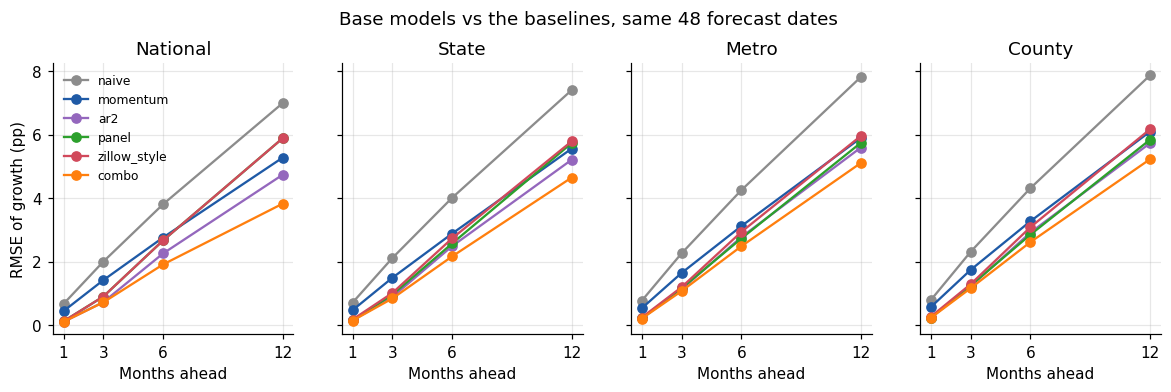

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
colors = {"naive": COLORS["grey"], "momentum": COLORS["ours"], "ar2": "#9467bd", "panel": "#2ca02c",
          "zillow_style": COLORS["zillow"], "combo": "#ff7f0e"}
for ax, level in zip(axes, order):
    for m in base_methods:
        g = base[(base["level"] == level) & (base["method"] == m)]
        ax.plot(g["h"], g["rmse_pp"], marker="o", label=m, color=colors[m])
    ax.set_title(level)
    ax.set_xlabel("Months ahead")
    ax.set_xticks([1, 3, 6, 12])
axes[0].set_ylabel("RMSE of growth (pp)")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Base models vs the baselines, same 48 forecast dates", y=1.03)
save(fig, "03_base_models")

## 2. Turning points: errors by period

The 2022-23 rate shock is where momentum failed. Did models that see mortgage rates, or that
lean on national growth, do better there?

In [4]:
reg = bt.score(res[res["method"].isin(base_methods) & res["level"].isin(["Metro", "County"])],
               by=("method", "level", "regime", "h"))
write_metrics("03_base_by_regime", reg)
reg[reg["h"] == 12].pivot_table(index=["level", "regime"], columns="method", values="rmse_pp", observed=True)[
    base_methods].round(2)

method                   naive  momentum   ar2  panel  zillow_style  combo
level  regime                                                             
Metro  Recovery 2012-20   5.91      3.61  3.46   3.99          4.24   3.43
       Pandemic boom     13.39      7.44  7.66   8.90          6.28   8.12
       Rate shock         8.78     10.65  7.62   6.12          7.15   6.11
       Flat 2024+         4.28      4.50  5.95   5.55          7.69   4.42
County Recovery 2012-20   5.90      3.88  3.60   4.15          4.36   3.58
       Pandemic boom     13.48      7.56  7.87   8.62          6.50   8.10
       Rate shock         8.74     10.71  7.56   6.13          7.31   6.08
       Flat 2024+         4.52      4.92  6.15   6.04          8.02   4.80

## 3. Reconciliation: does making the numbers add up cost accuracy?

For each base model, the coherent versions. Skill = 1 - RMSE / RMSE of the same model before
reconciliation (positive = reconciliation helped).

In [5]:
rec_rows = []
for b in BASES:
    for rname in RECONCILERS:
        s = scores[scores["method"] == f"{b}+{rname}"].merge(
            scores[scores["method"] == b][["level", "h", "rmse_pp"]], on=["level", "h"], suffixes=("", "_base"))
        s["base"], s["reconciler"] = b, rname
        s["skill_vs_base"] = 1 - s["rmse_pp"] / s["rmse_pp_base"]
        rec_rows.append(s)
rec = pd.concat(rec_rows)
write_metrics("03_reconciliation", rec)
rec[rec["h"] == 12].pivot_table(index=["base", "reconciler"], columns="level", values="rmse_pp", observed=True)[order].round(2)

level                     National  State  Metro  County
base         reconciler                                 
ar2          bottom_up        4.54   5.10   5.58    5.73
             mint_shrink      5.19   5.56   6.04    6.26
             wls_struct       4.59   5.27   7.02   10.06
             wls_var          4.55   5.11   5.58    5.73
combo        bottom_up        4.29   4.65   5.06    5.22
             mint_shrink      4.79   4.97   5.54    5.74
             wls_struct       4.05   4.86   9.13   16.62
             wls_var          4.28   4.65   5.07    5.23
momentum     bottom_up        5.35   5.57   5.90    6.09
             mint_shrink      5.00   5.28   5.66    5.86
             wls_struct       5.32   5.54   5.88    6.17
             wls_var          5.35   5.57   5.90    6.09
panel        bottom_up        5.25   5.43   5.69    5.84
             mint_shrink      7.00   6.77   7.14    7.30
             wls_struct       5.05   7.65  16.77   27.49
             wls_var          5.28   5.46   5.71    5.85
zillow_style bottom_up        5.90   5.79   5.96    6.16
             mint_shrink      5.64   5.64   5.86    6.07
             wls_struct       5.90   5.80   6.08    6.52
             wls_var          5.90   5.79   5.96    6.16

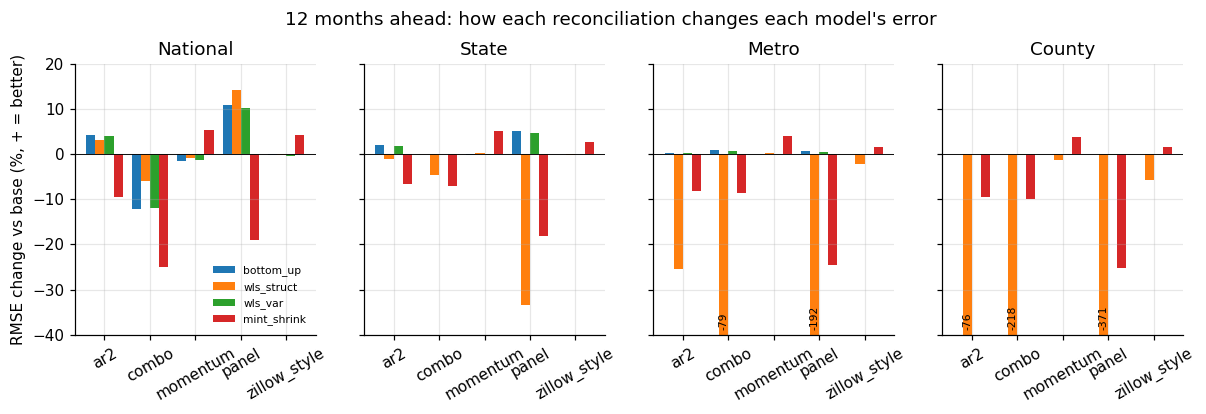

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, level in zip(axes, order):
    d = rec[(rec["level"] == level) & (rec["h"] == 12)].pivot(index="base", columns="reconciler", values="skill_vs_base")
    d = d[RECONCILERS] * 100
    d.plot.bar(ax=ax, legend=(level == "National"), width=0.8, rot=30)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylim(-40, 20)
    for i, b in enumerate(d.index):            # bars beyond the axis: print their value at the edge
        for j, rname in enumerate(RECONCILERS):
            v = d.loc[b, rname]
            if v < -40:
                ax.text(i - 0.3 + 0.2 * j, -39, f"{v:.0f}", rotation=90, fontsize=7, va="bottom", ha="center")
    ax.set_title(level)
    ax.set_xlabel("")
axes[0].set_ylabel("RMSE change vs base (%, + = better)")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("12 months ahead: how each reconciliation changes each model's error", y=1.03)
save(fig, "03_reconciliation_skill")

**Reading the reconciliation result.**
* **Bottom-up and wls_var are almost identical.** In dollars, a county's past error variance is
  tiny next to a state's or the nation's, so wls_var leaves the counties nearly untouched and moves the
  aggregates: in effect, bottom-up.
* **wls_struct is badly wrong.** Its weights count counties but ignore size. It spreads the nation's
  dollar disagreement over counties as if a rural county and Los Angeles were equally able to
  absorb it, which wrecks the small ones.
* **mint_shrink helps the weaker models and hurts the stronger ones.** With roughly 60 past error vectors for 2,000+
  nodes, the estimated covariance is noisy even after shrinkage. It improves momentum and the
  Zillow-style model, but adds noise to forecasts that are already good at county level.
* **The trade-off.** Bottom-up makes the national forecast exactly the sum of counties, so the nation
  gives up a little accuracy (combo: 3.8 pp as a direct forecast vs 4.3 pp added up at 12 months) in return for
  every level agreeing.

## 4. The chosen forecast

Chosen on the backtest alone: the coherent method with the lowest average RMSE across the four
levels and four horizons (each level weighted equally, so the 1,371 counties do not drown out the nation).

In [7]:
coherent = scores[scores["method"].str.contains(r"\+")]
avg = coherent.groupby("method", observed=True)["rmse_pp"].mean().sort_values()
chosen = avg.index[0]
mom = scores[scores["method"] == "momentum"].groupby("method", observed=True)["rmse_pp"].mean().iloc[0]
write_metrics("03_selection", {"chosen": chosen, "avg_rmse_pp": float(avg.iloc[0]),
                               "momentum_avg_rmse_pp": float(mom), "ranking": avg.round(4).to_dict()})
print(f"Chosen: {chosen}   (average RMSE {avg.iloc[0]:.2f} pp vs momentum {mom:.2f} pp)")
avg.head(8).round(3).to_frame("average RMSE (pp)")

Chosen: combo+bottom_up   (average RMSE 2.05 pp vs momentum 2.70 pp)


,average RMSE (pp)
method,
combo+bottom_up,2.055
combo+wls_var,2.056
ar2+bottom_up,2.239
ar2+wls_var,2.244
combo+mint_shrink,2.283
panel+bottom_up,2.350
panel+wls_var,2.355
ar2+mint_shrink,2.412


In [8]:
final = scores[scores["method"].isin([chosen, "momentum", "naive"])]
tab = final.pivot_table(index=["level", "h"], columns="method", values="rmse_pp", observed=True).reindex(order, level=0)
tab["skill_vs_momentum"] = 1 - tab[chosen] / tab["momentum"]
write_metrics("03_final_vs_momentum", tab.reset_index())
tab.round(3)

method       combo+bottom_up  momentum  naive  skill_vs_momentum
level    h                                                      
National 1             0.120     0.451  0.677              0.734
         3             0.707     1.425  2.008              0.504
         6             1.882     2.765  3.810              0.320
         12            4.291     5.273  6.986              0.186
State    1             0.157     0.482  0.720              0.674
         3             0.855     1.501  2.123              0.430
         6             2.135     2.890  4.015              0.261
         12            4.649     5.559  7.398              0.164
Metro    1             0.217     0.540  0.776              0.599
         3             1.080     1.650  2.266              0.345
         6             2.473     3.122  4.252              0.208
         12            5.058     5.895  7.808              0.142
County   1             0.239     0.579  0.799              0.588
         3             1.172     1.748  2.317              0.330
         6             2.621     3.276  4.316              0.200
         12            5.223     6.091  7.859              0.143

By period, metros, 12 months ahead:

In [9]:
fr = bt.score(res[res["method"].isin([chosen, "momentum", "naive"]) & (res["level"] == "Metro")],
              by=("method", "regime", "h"))
write_metrics("03_final_by_regime", fr)
fr[fr["h"] == 12].pivot_table(index="regime", columns="method", values="rmse_pp", observed=True).round(2)

method,combo+bottom_up,momentum,naive
regime,,,
Recovery 2012-20,3.44,3.61,5.91
Pandemic boom,7.96,7.44,13.39
Rate shock,6.00,10.65,8.78
Flat 2024+,4.47,4.50,4.28


## 5. What the panel model learned

Coefficients of the 12-month county and metro regressions at the last forecast date, in natural
units (growth in log points per unit of each feature). The mortgage-rate rows answer "what does
a 1-point rise in mortgage rates over a year usually mean for the next 12 months' price growth?"

In [10]:
c12 = coefs[coefs["h"] == 12].set_index("level").drop(columns="h").T[["National", "State", "Metro", "County"]]
write_metrics("03_panel_coefficients_h12", c12.reset_index(names="feature"))
c12.round(4)

level,National,State,Metro,County
const,0.0361,0.0316,0.0295,0.0302
g1,6.0474,5.7447,4.5404,4.1290
g3,-1.1426,-0.7865,-0.7191,-0.7197
g12,0.0797,0.1962,0.2556,0.2572
g12_prev,0.1489,0.1088,0.1310,0.1445
us12,0.0797,-0.0353,0.0130,0.0253
d_rate12,-0.0019,-0.0042,-0.0064,-0.0075
rate_gap,-0.0221,-0.0151,-0.0136,-0.0134
d_unemp12,0.0052,0.0044,0.0050,0.0052


## 6. How uncertain? Time-safe prediction intervals

Each interval is the forecast +/- a multiple of the node's own past error spread, the multiple set
from past errors of nodes at the same level (a simple conformal method). Only errors already known at
the forecast date are used. A good 80% interval covers about 80% of outcomes.

In [11]:
cov = bt.conformal_coverage(res[res["method"] == chosen])
write_metrics("03_interval_coverage", cov)
cov.pivot_table(index=["level", "h"], columns="nominal", values=["coverage", "median_width_pp"]).reindex(
    order, level=0).round(3)

coverage        median_width_pp        
nominal         0.80   0.95            0.80    0.95
level    h                                         
National 1     0.692  0.846           0.194   0.326
         3     0.538  0.769           0.838   1.311
         6     0.500  0.816           2.121   2.449
         12    0.694  0.861           5.853  12.457
State    1     0.725  0.902           0.262   0.457
         3     0.670  0.897           1.242   2.201
         6     0.653  0.882           2.862   4.793
         12    0.704  0.888           8.313  13.803
Metro    1     0.766  0.915           0.434   0.684
         3     0.726  0.908           1.898   3.143
         6     0.701  0.885           4.137   6.676
         12    0.728  0.889           9.868  15.966
County   1     0.766  0.916           0.465   0.726
         3     0.728  0.909           2.069   3.409
         6     0.704  0.885           4.398   7.094
         12    0.724  0.886          10.185  16.503

## 7. Against Zillow's published accuracy (same caveats as notebook 02)

In [12]:
zc = bt.zillow_comparison(res[res["method"].isin([chosen, "momentum"])], Y)
write_metrics("03_zillow_comparison", zc.reset_index())
zc.round(4)

h,1,3,6
method,,,
combo+bottom_up,0.0020,0.0116,0.0303
momentum,0.0054,0.0172,0.0332
Zillow (published),0.0105,0.0213,0.0388
